# 01 · Check the CAMELYON17 metadata

This is an exploratory check of that expectation against the public AWS copy. I'll keep the four slide-label categories separate.
I want to understand which slides have labels before downloading the images. I'll also check how the labels vary by hospital and how much storage the images would need.

Run the cells from top to bottom in the project's uv environment... The later sections cover file availability, checksums, hospital comparisons, and storage.



## 1. Load the metadata

- The first cell calls the metadata downloader. If the metadata is missing, it downloads three small text files and lists the files in the public AWS bucket. Later runs check that the saved metadata has not changed and reuse it offline. 
- Whole-slide images, masks, and XML annotations are not downloaded.

The output shows when the saved metadata was fetched and which Python and package versions are running.


In [ ]:
from pathlib import Path, PurePosixPath
from importlib.metadata import version
import csv
import hashlib
import json
import platform
import re
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = next(
    folder for folder in (Path.cwd(), *Path.cwd().parents)
    if (folder / "src" / "fetch_camelyon17_metadata.py").is_file()
)
sys.path.insert(0, str(ROOT / "src"))

# ----
from fetch_camelyon17_metadata import fetch_metadata

RAW = fetch_metadata()
DERIVED = ROOT / "data" / "derived" / "camelyon17"
DERIVED.mkdir(parents=True, exist_ok=True)
provenance = json.loads((RAW / "provenance.json").read_text(encoding="utf-8"))
software = {"python": platform.python_version()}
software.update({name: version(name) for name in ("pandas", "numpy", "boto3", "matplotlib")})
print("Snapshot retrieved (UTC):", provenance["retrieved_at_utc"])
display(pd.Series(software, name="version").to_frame())

Using the verified local metadata snapshot.
Snapshot retrieved (UTC): 2026-10-21T23:43:20.479989+00:00


,version
python,3.13.18
pandas,3.0.6
numpy,2.5.4
boto3,1.43.116
matplotlib,3.11.2


## 2. Read the label table

The downloaded README describes H&E-stained lymph-node slides from five medical centers in the Netherlands. The classification task is to identify breast-cancer metastases in those lymph nodes.

| File or field | What it contains |
|---|---|
| `stages.csv: patient` | A slide filename ending in `.tif`, or a record for a slide group ending in `.zip`. A row can describe either a slide or a group of slides. |
| `stages.csv: stage` | A category for that row. Slides use `negative`, `itc`, `micro`, or `macro`. Groups use `pN0`, `pN0(i+)`, `pN1mi`, `pN1`, or `pN2`. |
| `stages.csv: center` | A hospital code from 0 to 4. I keep these integer codes because the order of hospital names in the README does not establish which name belongs to each code. |
| `objects.csv: key` | The location of a file in the public S3 bucket. This CSV is a file list; it contains no image data. |
| `objects.csv: size_bytes` | The space a stored file takes, in bytes. It does not give the image's pixel dimensions or the memory needed to decode it. |
| `checksums.md5` | The publisher's hashes for checking downloaded files. An S3 ETag is not assumed to be an MD5 hash. |



The next cell reads both CSV files and checks their columns and row structure. It also checks for missing cells, duplicate rows, and repeated identifiers. Empty or whitespace-only cells count as missing. The label checks stop at an unknown category instead of silently treating it as a missing value.

I use "slide group" to mean five real lymph-node slide images grouped together for the challenge. The organizers call this an "artificial patient": they assembled the group using slides that can come from different real patients. The images are real; the grouping was constructed for the challenge, which asks a model to assign one staging label to the whole group.

Keeping a slide group together does not by itself establish independence between real patients. The [official evaluation description](https://camelyon17.grand-challenge.org/Evaluation/) and [dataset paper](https://pmc.ncbi.nlm.nih.gov/articles/PMC6007545/) explain how these groups were constructed.


In [ ]:
def check(condition, message):
    if not condition:
        raise ValueError(message)


def read_csv_checked(path, expected_columns):
    # Bound local input before parsing. Do not skip malformed or excess rows.
    cursor = ROOT
    for part in path.relative_to(ROOT).parts:
        cursor = cursor / part
        check(not cursor.is_symlink(), "Symlinks are not accepted for audit input.")
    check(path.is_file() and path.stat().st_nlink == 1, "Expected one regular local file.")
    check(path.stat().st_size <= 8 * 1024**2, "CSV exceeds the 8 MiB audit limit.")
    csv.field_size_limit(4096)
    with path.open(encoding="utf-8-sig", newline="") as stream:
        reader = csv.reader(stream, strict=True)
        header = next(reader)
        check(header == expected_columns, "Unexpected CSV schema.")
        rows = []
        for row in reader:
            check(len(row) == len(header), "Non-rectangular CSV record.")
            check(len(rows) < 20_000, "CSV exceeds the row limit; audit stopped.")
            rows.append(row)
    return pd.DataFrame(rows, columns=header)


labels = read_csv_checked(RAW / "stages.csv", ["patient", "stage", "center"])
objects = read_csv_checked(
    RAW / "objects.csv", ["key", "size_bytes", "etag", "last_modified_utc"]
)
missing_cells = int(labels.apply(lambda column: column.str.strip().eq("").sum()).sum())
duplicate_records = int(labels.duplicated().sum())
duplicate_identifiers = int(labels["patient"].duplicated().sum())

check(missing_cells == 0, "Missing cells in the published label table.")
check(duplicate_records == 0 and duplicate_identifiers == 0, "Duplicate label records.")
check(labels["center"].str.fullmatch(r"[0-4]").all(), "Unexpected hospital code.")
check(not objects["key"].duplicated().any(), "Duplicate object keys.")
check(objects["size_bytes"].str.fullmatch(r"\d+").all(), "Invalid object size.")

objects["size_bytes"] = objects["size_bytes"].astype("int64")
print(f"Read all {len(labels):,} label-table rows and all {len(objects):,} inventory rows.")

display(pd.Series({
    "Missing label-table cells": missing_cells,
    "Duplicate label-table rows": duplicate_records,
    "Duplicate label identifiers": duplicate_identifiers,
    "Duplicate inventory keys": int(objects["key"].duplicated().sum()),
}, name="count").to_frame())

Read all 600 label-table rows and all 1,157 inventory rows.


,count
Missing label-table cells,0
Duplicate label-table rows,0
Duplicate label identifiers,0
Duplicate inventory keys,0


## 3. Count slides and groups separately

The saved CSV has 600 rows: 500 labels for individual slides and 100 staging labels for slide groups. Each group contains five slides and has one additional row for its combined staging label. That gives six CSV rows for five images.

The ZIP names identify the groups in the CSV. Our saved AWS file list contains individual TIFF images and no ZIP archives.

The code separates the two record types by their filenames. It then checks that each group has five slides and that each slide has the same hospital code as its group.


In [3]:
SLIDE_LABELS = ["negative", "itc", "micro", "macro"]
GROUP_STAGES = ["pN0", "pN0(i+)", "pN1mi", "pN1", "pN2"]

is_slide = labels["patient"].str.fullmatch(r"patient_\d{3}_node_[0-4]\.tif")
is_group = labels["patient"].str.fullmatch(r"patient_\d{3}\.zip")
check((is_slide | is_group).all(), "Unrecognized label record type.")

slides = labels.loc[is_slide].rename(columns={"patient": "slide_id", "stage": "label"}).copy()
groups = labels.loc[is_group].rename(columns={"patient": "group_record"}).copy()
slides["group_id"] = slides["slide_id"].str.extract(r"^(patient_\d{3})", expand=False)
groups["group_id"] = groups["group_record"].str.removesuffix(".zip")
slides["center"] = slides["center"].astype(int)
groups["center"] = groups["center"].astype(int)

check(slides["label"].isin(SLIDE_LABELS).all(), "Unrecognized slide label.")
check(groups["stage"].isin(GROUP_STAGES).all(), "Unrecognized group stage.")
check(set(slides["group_id"]) == set(groups["group_id"]), "Slide/group membership mismatch.")
check(slides.groupby("group_id").size().eq(5).all(), "A group does not have five slides.")
group_membership = slides.merge(
    groups[["group_id", "center"]], on="group_id", validate="many_to_one",
    suffixes=("_slide", "_group")
)
check(
    group_membership["center_slide"].eq(group_membership["center_group"]).all(),
    "Hospital code differs between a slide and its group.",
)
display(pd.Series({
    "Slide-label records": len(slides),
    "Artificial patient-group records": len(groups),
}, name="records").to_frame())

,records
Slide-label records,500
Artificial patient-group records,100


## 4. Match labels to image files

Each slide filename is matched to its entry in the file list. Whole-slide images are counted only under `images/`; XML annotations and masks are counted separately.

Some listed images have no label in this CSV. Those labels stay missing, because an absent label does not mean the image is negative. At this point, the counts tell us which files are listed. Their contents still need to be inspected.


In [4]:
image_pattern = r"CAMELYON17/images/(patient_\d{3}_node_[0-4]\.tif)"
image_match = objects["key"].str.fullmatch(image_pattern)
check(
    objects["key"].str.startswith("CAMELYON17/images/").eq(image_match).all(),
    "Unexpected entries in the images directory; inspect before counting.",
)
image_files = objects.loc[image_match].copy()
image_files["slide_id"] = image_files["key"].str.extract(image_pattern, expand=False)
image_files["group_id"] = image_files["slide_id"].str.extract(r"^(patient_\d{3})", expand=False)
check(not image_files["slide_id"].duplicated().any(), "Duplicate slide filenames.")
check(image_files["size_bytes"].gt(0).all(), "An image has zero stored bytes.")

inventory = image_files.merge(
    slides[["slide_id", "label", "center"]], on="slide_id", how="left", validate="one_to_one"
)
inventory["center"] = inventory["center"].astype("Int64")
inventory["has_label"] = inventory["label"].notna()
check(int(inventory["has_label"].sum()) == len(slides), "A labeled slide is missing from the listing.")

annotation_pattern = r"CAMELYON17/annotations/(patient_\d{3}_node_[0-4])\.xml"
annotation_match = objects["key"].str.fullmatch(annotation_pattern)
check(
    objects["key"].str.startswith("CAMELYON17/annotations/").eq(annotation_match).all(),
    "Unexpected annotation filename.",
)
annotations = objects.loc[annotation_match, ["key"]].copy()
annotations["slide_id"] = annotations["key"].str.extract(annotation_pattern, expand=False) + ".tif"
check(annotations["slide_id"].isin(slides["slide_id"]).all(), "Annotation without a training label.")
annotation_keys = annotations.set_index("slide_id")["key"]
inventory["annotation_key"] = inventory["slide_id"].map(annotation_keys)
inventory["has_annotation"] = inventory["annotation_key"].notna()
mask_count = int(objects["key"].str.startswith("CAMELYON17/masks/").sum())

display(pd.Series({
    "Whole-slide image files": len(inventory),
    "Images with a label in this CSV": int(inventory["has_label"].sum()),
    "Images without a label in this CSV": int((~inventory["has_label"]).sum()),
    "XML annotation files listed": len(annotations),
    "Mask files listed": mask_count,
}, name="count").to_frame())

,count
Whole-slide image files,1000
Images with a label in this CSV,500
Images without a label in this CSV,500
XML annotation files listed,50
Mask files listed,100


## 5. Check the downloaded files

A checksum is a value calculated from a file's contents. The code compares the downloaded README and label CSV with the publisher's MD5 hashes to check that they match.

For the slide images, I save the expected MD5 hashes for later. Their contents can be checked after downloading them. Finding a filename in the file list or checksum list does not verify the image itself.


In [5]:
checksum_file = RAW / "checksums.md5"
check(checksum_file.stat().st_size <= 8 * 1024**2, "Checksum list exceeds the audit limit.")
checksums = {}
for line in checksum_file.read_text(encoding="utf-8").splitlines():
    if not line.strip():
        continue
    match = re.fullmatch(r"([0-9a-fA-F]{32})\s+\*?(.+)", line)
    check(match is not None, "Malformed checksum record.")
    digest, relative_path = match.groups()
    parts = PurePosixPath(relative_path)
    check(not parts.is_absolute() and ".." not in parts.parts, "Unexpected checksum path.")
    key = "CAMELYON17/" + relative_path
    check(key not in checksums, "Duplicate checksum entry.")
    checksums[key] = digest.lower()

for filename in ("README.md", "stages.csv"):
    digest = hashlib.md5((RAW / filename).read_bytes(), usedforsecurity=False).hexdigest()
    check(digest == checksums.get("CAMELYON17/" + filename), "Downloaded metadata checksum mismatch.")

inventory["expected_md5"] = inventory["key"].map(checksums)
check(inventory["expected_md5"].notna().all(), "A slide has no published checksum.")
print("README and label CSV match the published MD5 checksums.")
print(f"Expected image checksums recorded: {inventory['expected_md5'].notna().sum():,}.")
print("No image-content checksum checks performed; images have not been downloaded.")

README and label CSV match the published MD5 checksums.
Expected image checksums recorded: 1,000.
No image-content checksum checks performed; images have not been downloaded.


## 6. Count labels by hospital

Each row in the first output is a hospital, and each label column counts slides in that category. The saved snapshot has 100 labeled slides per hospital, although the mix of labels differs. These counts describe this release; they do not estimate how common metastasis is in clinical practice.

ITC means isolated tumor cells. I keep this category separate until the binary classification target is defined. The remaining tables show group and annotation counts, slide storage per hospital, and group staging counts.


In [6]:
labeled = inventory.loc[inventory["has_label"]].copy()
label_counts = pd.crosstab(slides["center"], slides["label"]).reindex(
    index=range(5), columns=SLIDE_LABELS, fill_value=0
)
label_counts.index.name = "hospital"
label_counts["total"] = label_counts[SLIDE_LABELS].sum(axis=1)
display(label_counts)

hospital_coverage = pd.DataFrame({
    "artificial_groups": groups.groupby("center").size(),
    "xml_annotations": labeled.groupby("center")["has_annotation"].sum(),
    "stored_GB": labeled.groupby("center")["size_bytes"].sum() / 1e9,
})
hospital_coverage.index.name = "hospital"
display(hospital_coverage.round(2))
display(
    groups["stage"].value_counts().reindex(GROUP_STAGES, fill_value=0)
    .rename_axis("group_stage").rename("groups").to_frame()
)

label,negative,itc,micro,macro,total
hospital,,,,,
0,64,11,10,15,100
1,58,7,23,12,100
2,75,2,8,15,100
3,60,8,13,19,100
4,61,8,5,26,100


,artificial_groups,xml_annotations,stored_GB
hospital,,,
0,20,10,261.81
1,20,10,471.59
2,20,10,308.90
3,20,10,321.22
4,20,10,97.84


,groups
group_stage,
pN0,24
pN0(i+),11
pN1mi,21
pN1,30
pN2,14


## 7. Estimate image storage

The first table adds up the full TIFF file sizes for all images and for the labeled subset. GB and TB use decimal units (`10^9` and `10^12` bytes); GiB uses `2^30` bytes.

These totals exclude masks, downloaded tiles, features, and model checkpoints. They also exclude the memory needed to decode the images. The AWS copy can differ in size from the original published release.

The second table describes the spread of file sizes. The mean and median show typical sizes; SD is the standard deviation, and MAD is the median absolute distance from the median. Q1 and Q3 are the 25th and 75th percentiles, and IQR is the difference between them. Files above `Q3 + 1.5 × IQR` are flagged for inspection and kept in the storage totals.

The plots show the label counts by hospital and the file-size distribution of labeled slides. The dashed line marks the median file size.


In [7]:
storage_rows = []
distribution_rows = []
for name, cohort in [("All image files", inventory), ("Labeled image files", labeled)]:
    sizes = cohort["size_bytes"].astype(float) / 1e9
    q1, median, q3 = sizes.quantile([0.25, 0.5, 0.75])
    storage_rows.append({
        "cohort": name, "slides": len(cohort),
        "total_bytes": int(cohort["size_bytes"].sum()),
        "TB": cohort["size_bytes"].sum() / 1e12,
        "GiB": cohort["size_bytes"].sum() / 1024**3,
    })
    distribution_rows.append({
        "cohort": name, "mean_GB": sizes.mean(), "SD_GB": sizes.std(),
        "median_GB": median, "Q1_GB": q1, "Q3_GB": q3,
        "MAD_GB": (sizes - median).abs().median(),
        "max_GB": sizes.max(),
        "above_upper_IQR_fence": int((sizes > q3 + 1.5 * (q3 - q1)).sum()),
    })
storage = pd.DataFrame(storage_rows).set_index("cohort")
size_distribution = pd.DataFrame(distribution_rows).set_index("cohort")
display(storage.round(3))
display(size_distribution.round(3))

,slides,total_bytes,TB,GiB
cohort,,,,
All image files,1000,2973774738350,2.974,2769.544
Labeled image files,500,1461349695544,1.461,1360.988


,mean_GB,SD_GB,median_GB,Q1_GB,Q3_GB,MAD_GB,max_GB,above_upper_IQR_fence
cohort,,,,,,,,
All image files,2.974,1.620,2.821,1.781,3.972,1.087,9.372,11
Labeled image files,2.923,1.565,2.759,1.832,3.898,1.063,8.424,8


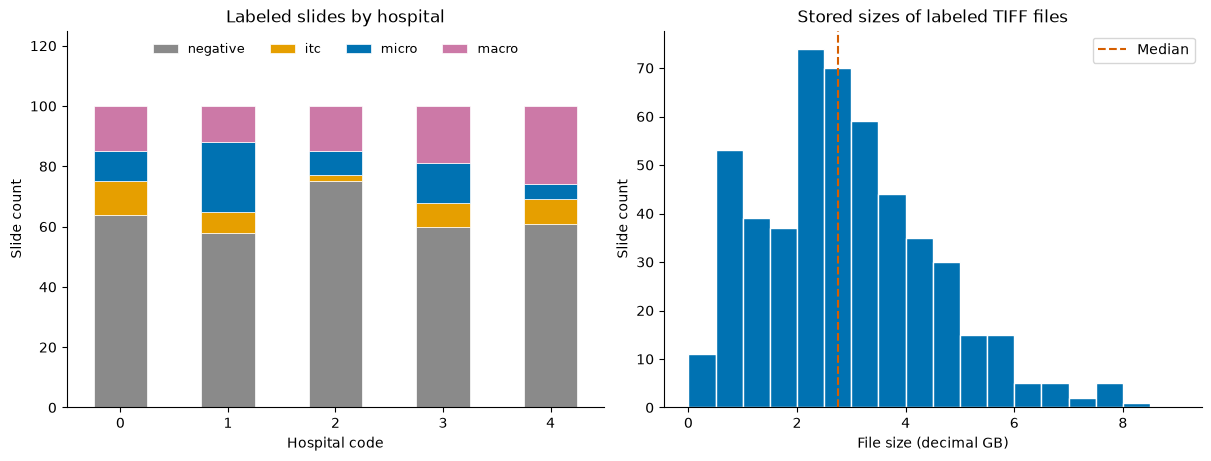

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
label_counts[SLIDE_LABELS].plot.bar(
    stacked=True, ax=axes[0], color=["#8A8A8A", "#E69F00", "#0072B2", "#CC79A7"],
    edgecolor="white", linewidth=0.5,
)
axes[0].set(title="Labeled slides by hospital", xlabel="Hospital code", ylabel="Slide count")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(ncol=4, loc="upper center", fontsize=9, frameon=False)
axes[0].set_ylim(0, label_counts["total"].max() * 1.25)

sizes_gb = labeled["size_bytes"] / 1e9
axes[1].hist(sizes_gb, bins=np.linspace(0, np.ceil(sizes_gb.max()), 19), color="#0072B2", edgecolor="white")
axes[1].axvline(sizes_gb.median(), color="#D55E00", linestyle="--", label="Median")
axes[1].set(title="Stored sizes of labeled TIFF files", xlabel="File size (decimal GB)", ylabel="Slide count")
axes[1].legend()
for axis in axes:
    axis.spines[["top", "right"]].set_visible(False)
fig.savefig(DERIVED / "audit_overview.png", dpi=150)
fig.savefig(DERIVED / "audit_overview.svg")
plt.show()

## 8. Save the results

I save the complete per-slide inventory under the ignored `data/` directory. It includes file locations, labels where supplied, stored file sizes, annotation availability, and expected checksums. Images without a supplied label stay unlabeled.

The source hashes and retrieval time identify the saved metadata used for these results. A fresh clone can fetch the public metadata again, but changes to the source may produce different hashes and results. Keep the cached raw metadata and provenance file to reproduce this exact snapshot.


In [9]:
inventory.to_csv(DERIVED / "slide_inventory.csv", index=False)
label_counts.to_csv(DERIVED / "labels_by_hospital.csv")
hospital_coverage.to_csv(DERIVED / "coverage_by_hospital.csv")
storage.to_csv(DERIVED / "storage_summary.csv")
size_distribution.to_csv(DERIVED / "file_size_distribution.csv")

summary = {
    "snapshot_retrieved_at_utc": provenance["retrieved_at_utc"],
    "objects_listed": len(objects),
    "listing_complete": provenance["files"]["objects.csv"]["complete"],
    "label_csv_rows": len(labels),
    "labeled_slides": len(slides),
    "artificial_groups_with_stage": len(groups),
    "all_slides": len(inventory),
    "slides_without_label_in_csv": int((~inventory["has_label"]).sum()),
    "slide_labels": {label: int(slides["label"].eq(label).sum()) for label in SLIDE_LABELS},
    "xml_annotations_listed": len(annotations),
    "mask_files_listed": mask_count,
    "labeled_slide_bytes": int(labeled["size_bytes"].sum()),
    "all_slide_bytes": int(inventory["size_bytes"].sum()),
    "missing_label_table_cells": missing_cells,
    "duplicate_label_records": duplicate_records,
    "duplicate_label_identifiers": duplicate_identifiers,
    "metadata_md5_verified": True,
    "image_contents_inspected": False,
    "image_checksums_verified": False,
    "software": software,
    "source_sha256": {name: details["sha256"] for name, details in provenance["files"].items()},
}
(DERIVED / "summary.json").write_text(json.dumps(summary, indent=2) + "\n", encoding="utf-8")
derived_files = [
    "slide_inventory.csv", "labels_by_hospital.csv", "coverage_by_hospital.csv",
    "storage_summary.csv", "file_size_distribution.csv", "summary.json",
    "audit_overview.png", "audit_overview.svg",
]
derived_hashes = {
    name: hashlib.sha256((DERIVED / name).read_bytes()).hexdigest()
    for name in derived_files
}
(DERIVED / "derived_sha256.json").write_text(
    json.dumps(derived_hashes, indent=2) + "\n", encoding="utf-8"
)
display(Markdown(
    f"The CSV supplies labels for **{len(slides):,} slides** in "
    f"**{slides['center'].nunique()} hospitals**, plus staging labels for "
    f"**{len(groups):,} artificial groups**. The labeled slide files occupy "
    f"**{labeled['size_bytes'].sum() / 1e12:.3f} TB** in this AWS snapshot; "
    f"the full image listing occupies **{inventory['size_bytes'].sum() / 1e12:.3f} TB**."
))

The CSV supplies labels for **500 slides** in **5 hospitals**, plus staging labels for **100 artificial groups**. The labeled slide files occupy **1.461 TB** in this AWS snapshot; the full image listing occupies **2.974 TB**.

## What I still need to check

- The other images have no labels in this CSV. This check says nothing about labels in other dataset releases.
- The slide and group membership checks passed. Their relationship to real patients still limits what I can claim about patient independence and data leakage.
- I have not opened any images or annotation contents. Pixel dimensions, micrometers per pixel, pyramid levels, staining differences, and image integrity still need direct inspection.
- The challenge documentation says isolated tumor cells were not annotated exhaustively. An XML file may therefore lack tumor outlines for some lesions.
- I have not defined a binary label, created model splits, or trained a model. Those decisions belong in the analysis plan.

After understanding the metadata, the next step is to open a small sample of images, check their resolution metadata, and compare an annotated slide with its tumor outline.


## Sources and software

- [CAMELYON on AWS Open Data](https://registry.opendata.aws/camelyon/): public bucket, region, and CC0 license. Accessed 2026-10-22.
- The bucket's `CAMELYON17/README.md`, `stages.csv`, and `checksums.md5`, plus the full file listing. Local copies and hashes are saved with this audit.
- [CAMELYON17 data documentation](https://camelyon17.grand-challenge.org/Data/): image format, annotation coverage, and ITC limitations.
- [CAMELYON17 evaluation documentation](https://camelyon17.grand-challenge.org/Evaluation/): how the slide groups were constructed.
- Litjens et al. (2018). [1399 H&E-stained sentinel lymph node sections of breast cancer patients: the CAMELYON dataset](https://doi.org/10.1093/gigascience/giy065).
- The `exploratory-data-analysis` skill, version 1.4, helped summarize and check the local CSV files within file-size and row limits. Kassis, T., Agarwal, V., He, Y., Patel, D., and Brueckner, A. M. (2026). [Scientific Agent Skills: A Library of Procedural Knowledge for Research Agents](https://doi.org/10.48550/arXiv.2609.00065). The notebook runs with the dependencies in `uv.lock`; the skill is not required to run it.
